# Thí nghiệm E1: GSM8K × Qwen2.5-0.5B-Instruct

Bài toán lời văn cấp tiểu học (GSM8K, bộ chuẩn công khai): mô hình giải từng bước rồi ghi con số cuối trong `\boxed{}`. Đây là bài toán thứ ba của đề tài, sau phép nhân và Countdown.

Notebook chạy theo đúng luồng của người nghiên cứu trên lab HeteroES:

| Bước | Ở đây |
|---|---|
| Mô hình | `Model.from_hf` ghim một commit Hugging Face; **mỗi máy tự tải từ Hugging Face** và kiểm SHA-256 từng tệp |
| Dữ liệu | `Dataset.from_rows` (train / validation / test cố định, ghim mã băm) |
| Chạy | `ESTrainer.submit(lab, coordinator, workers)`: lab xếp hàng, chia candidate cho các GPU, chấm chéo (audit) |
| Nối tiếp | mỗi đoạn sau bắt đầu từ trọng số cuối đã kiểm chứng của đoạn trước (`derive_model`) |
| Đánh giá | chọn checkpoint bằng validation; tập test chỉ chấm **một lần** ở cuối, kiểm định McNemar |

Các đoạn và lý do chọn tham số nằm ở `decisions/e1-gsm8k-qwen05.json`; mã thí nghiệm trên lab ở `state/e1-gsm8k-qwen05.json`. Chạy lại
notebook sẽ gắn vào các run đã có (không chạy lại). Đặt `CHAY_MOI = True` để chạy một run ngắn mới khi demo.

## 1. Chuẩn bị: kết nối lab và xem các GPU

In [1]:
import json
import sys
import time
from pathlib import Path

HERE = Path.cwd()
SRC = (HERE / ".." / ".." / "src").resolve()  # runtime/notebooks/experiments -> runtime/src
for path in (str(SRC), str(HERE)):
    if path not in sys.path:
        sys.path.insert(0, path)

import runner  # noqa: E402  (sets a clean Hugging Face cache first)
import tasks  # noqa: E402
from heteroes.sdk import ESConfig, ESTrainer, reward  # noqa: E402
from heteroes.sdk_lab import Dataset, Lab, Model  # noqa: E402

NAME = 'e1-gsm8k-qwen05'
CHAY_MOI = False  # True: a short new run for a live demo (a few generations) instead of re-attaching to the recorded one
COORDINATOR = "5070ti-nhan"  # the coordinator goes to a GPU (owner rule)
EXCLUDE = set()  # names of devices to leave out of a new segment

experiment = runner.Experiment(NAME + (time.strftime("-demo-%Y%m%d-%H%M") if CHAY_MOI else ""))
lab = Lab.from_session()  # python3 scripts/lab-login.py signs in once (12 hours)


def online_workers():
    return [d.name for d in lab.devices() if d.online and d.on and not d.cpu_only and d.name not in EXCLUDE]


for d in lab.devices():
    print(f"{d.name:16} {d.gpu:28} {d.vram_gb:5.1f} GB  online={d.online} ON={d.on} bận={d.busy}")

5070ti-nhan      NVIDIA GeForce RTX 5070 Ti    15.9 GB  online=True ON=True bận=True


## 2. Dữ liệu

In [2]:
splits = tasks.gsm8k()  # train less 500 seeded rows = validation; official test = test
data = Dataset.from_rows(**splits, directory=experiment.dir / "data")
print({k: len(v) for k, v in splits.items()}, "| mã băm dữ liệu", data.sha256[:16], "…")
print(splits["test"][0]["prompt"], "\n→ đáp án", splits["test"][0]["answer"])

{'train': 6973, 'validation': 500, 'test': 1319} | mã băm dữ liệu 61cea156c4c23aea …
Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?

Solve the problem step by step. Put only the final number inside \boxed{}, for example \boxed{42}. 
→ đáp án 18


/home/pc5070ti/miniforge3/envs/heteroes-match/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Mô hình

`Qwen/Qwen2.5-0.5B-Instruct` được ghim theo commit `7ae557604adf…`. Trên lab đây là mô hình **tham chiếu**: lab không giữ bản
sao, mỗi worker tự tải từ Hugging Face rồi kiểm tra mã băm từng tệp trước khi làm việc.

In [3]:
model = Model.from_hf('Qwen/Qwen2.5-0.5B-Instruct', revision='7ae557604adf67be50417f59c2c2f167def9a775')
print(model.id, model.revision[:12], model.source)
for file, sha in model.manifest["files"].items():
    print(f"  {file:28} {sha[:16]}…")

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 2948.10it/s]

Qwen/Qwen2.5-0.5B-Instruct 7ae557604adf REFERENCE
  config.json                  18e18afcaccafade…
  generation_config.json       e558847a8b440261…
  merges.txt                   599bab5407508877…
  model.safetensors            fdf756fa7fcbe740…
  tokenizer.json               c0382117ea329cdf…
  tokenizer_config.json        5b5d4f65d0acd3b2…
  vocab.json                   ca10d7e9fb3ed185…


## 4. Reward

Reward của một candidate là trung bình điểm trên lô 32 câu train. Trên tập test, **"đúng" nghĩa là điểm 1** (đáp án
chính xác).

In [4]:
SCORER = {"name": "boxed-number", "config": {"answerField": "answer", "formatReward": 0.1}}
TEST_SCORER = SCORER  # "đúng" = score 1: the boxed number equals the answer
make_reward = dict(scorer=SCORER)

### Mô hình gốc trả lời thế nào?

Ba câu test đầu, giải mã tham lam bằng bộ suy luận nghiêm ngặt `strict_b22_v1` như trong thí nghiệm (tối đa 320
token).

In [5]:
sample = splits["test"][:3]
before = runner.score_model(model.path, sample, TEST_SCORER, 320)
for row, text, s in zip(sample, before["outputs"], before["scores"]):
    print(f"[điểm {s}]", repr(text[-300:]))

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 6510.38it/s]

[điểm 1.0] "y} \\]\n\n**Step 3: Calculate the revenue from selling the eggs.**\n\nEach egg is sold for $2. So, the revenue from selling 9 eggs is:\n\\[ 9 \\text{ eggs/day} \\times 2 \\text{ dollars/egg} = 18 \\text{ dollars/day} \\]\n\nThus, the amount of money Janet makes at the farmers' market each day is:\n\\[\n\\boxed{18}\n\\]"
[điểm 1.0] 'white fiber needed is \\( \\frac{2}{2} = 1 \\) bolt.\n\n3. Calculate the total number of bolts needed:\n   - Add the number of blue fiber bolts to the number of white fiber bolts.\n   - Total bolts = Blue fiber bolts + White fiber bolts = 2 + 1 = 3.\n\nThus, the total number of bolts needed is \\(\\boxed{3}\\).'
[điểm 0.0] "\n\n3. **Calculate the profit:**\n   - The profit is the difference between the total value of the house after repairs and its original value.\n   - Profit = Total value after repairs - Original value\n   \\[\n   200,000 - 130,000 = 70,000\n   \\]\n\nTherefore, Josh's profit from flipping his house is \\(\\boxed"


## 5. Cấu hình

32 candidate mỗi thế hệ, mỗi candidate chấm trên 32 câu train; σ và α theo từng đoạn. Validation
(500 câu) được chấm mỗi 20 thế hệ trên coordinator.

In [6]:
def make_trainer(model, segment):
    args = ESConfig(
        model=model,
        dataset=data,
        population=32,
        batch_size=32,
        generations=3 if CHAY_MOI else segment["generations"],
        alpha=segment["alpha"],
        sigma=segment["sigma"],
        max_new_tokens=320,
        eval_dtype="float16",
        decoder="strict_b22_v1",  # same tokens on every supported NVIDIA GPU
        eval_chunk=32,
        validation_interval=20,
        audit_rate=0.05,
    )
    return ESTrainer(args, code_dir=experiment.dir / "code", **make_reward)


segments = experiment.segments({'alpha': 0.0005, 'sigma': 0.001, 'generations': 100, 'reason': 'tham số của Qiu et al. 2025 (ES cho LLM): σ = 0,001, α = 5·10⁻⁴, khoảng 30 candidate'})
for i, s in enumerate(segments, 1):
    print(f"đoạn {i}: α={s['alpha']} σ={s['sigma']} {s['generations']} thế hệ — {s['reason']}")

đoạn 1: α=0.0005 σ=0.001 100 thế hệ — tham số của Qiu et al. 2025 (ES cho LLM): σ = 0,001, α = 5·10⁻⁴, khoảng 30 candidate


## 6. Chạy trên lab

Mỗi đoạn là một experiment trên lab. Ô này chờ đến khi các đoạn xong (xem trực tiếp trên trang Experiments của lab);
khi chạy lại notebook, các đoạn đã có chỉ được gắn lại.

In [7]:
runs = runner.run_segments(lab, experiment, model, make_trainer, segments, COORDINATOR, online_workers)
for (segment, run, _), i in zip(runs, range(1, len(runs) + 1)):
    print(f"đoạn {i}: {run.id} {run.status()} {run.url}")

segment-01: α=0.0005 σ=0.001 100 thế hệ trên ['5070ti-nhan'] — lý do: tham số của Qiu et al. 2025 (ES cho LLM): σ = 0,001, α = 5·10⁻⁴, khoảng 30 candidate


  chờ ['5070ti-nhan'] rảnh…


Qualifying 5070ti-nhan for Qwen/Qwen2.5-0.5B-Instruct (a few minutes)…


  5070ti-nhan: qualified


Queued af5e244aa0f848c69176092a5a448ac7: https://lab.heteroes.site/experiments/af5e244aa0f848c69176092a5a448ac7


đoạn 1: af5e244aa0f848c69176092a5a448ac7 COMPLETED https://lab.heteroes.site/experiments/af5e244aa0f848c69176092a5a448ac7


## 7. Quá trình học

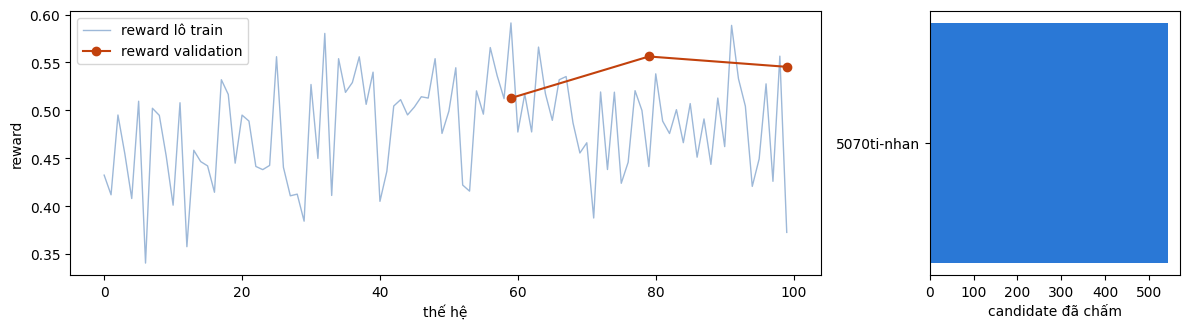

validation: [(59, 0.5128), (79, 0.5562), (99, 0.5454)]


In [8]:
import matplotlib.pyplot as plt

rewards, validation, work = runner.history(runs)
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [3, 1]})
a.plot([g for g, _ in rewards], [r for _, r in rewards], color="#9db8d8", lw=1, label="reward lô train")
a.plot([g for g, _ in validation], [r for _, r in validation], "o-", color="#c2410c", label="reward validation")
for end in [sum(s["generations"] for s, _, _ in runs[:k]) for k in range(1, len(runs))]:
    a.axvline(end - 0.5, color="#999", ls=":", lw=1)
a.set_xlabel("thế hệ")
a.set_ylabel("reward")
a.legend()
names = {d.worker_id: d.name for d in lab.devices()}
b.barh([names.get(w, w) for w in work], list(work.values()), color="#2a78d6")
b.set_xlabel("candidate đã chấm")
plt.tight_layout()
plt.show()
print("validation:", [(g, round(r, 4)) for g, r in validation])

## 8. Chọn checkpoint và chấm test (một lần)

Checkpoint được chọn là cuối đoạn có reward validation cao nhất. Tập test được chấm cho mô hình gốc, cuối đoạn đầu và
checkpoint được chọn; kết quả lưu lại nên chạy lại notebook không chấm lại.

In [9]:
ends = []
for k, (segment, run, _) in enumerate(runs, 1):
    marks = [v for v in run.results()["validation"] if v["generation"] is not None]
    ends.append((marks[-1]["reward"], k))
best = max(ends)[1]
print("validation cuối mỗi đoạn:", ends, "→ chọn đoạn", best)

done = [(s, r, m) for s, r, m in runs]
first_dir = runner.after_segment(lab, experiment, done, 1).path
best_dir = runner.after_segment(lab, experiment, done, best).path
rows = splits["test"]
base = runner.test_report(experiment, "base", -1, model.path, rows, TEST_SCORER, 320)
first = runner.test_report(experiment, "first", 1, first_dir, rows, TEST_SCORER, 320)
chosen = runner.test_report(experiment, f"segment-{best:02d}", best, best_dir, rows, TEST_SCORER, 320)
for label, report in (("mô hình gốc", base), ("cuối đoạn 1", first), (f"chọn (đoạn {best})", chosen)):
    ok, n = runner.correct(report)
    print(f"{label:16} đúng {ok}/{n} = {ok / n:6.1%}   reward {report['checkpoints'][0]['meanReward']:.4f}")

validation cuối mỗi đoạn: [(0.5454, 1)] → chọn đoạn 1


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 6280.55it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 16875.44it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

... (4 outputs left out)

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 19610.93it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 17905.91it/s]

mô hình gốc      đúng 462/1319 =  35.0%   reward 0.3811
cuối đoạn 1      đúng 528/1319 =  40.0%   reward 0.4440
chọn (đoạn 1)    đúng 528/1319 =  40.0%   reward 0.4440


In [10]:
from heteroes.v3.comparison import compare

result = compare(base, chosen)
print(f"gốc → chọn: sửa đúng {result['fixed']}, làm sai {result['broke']}, McNemar p = {result['mcnemarExactP']:.2g}, "
      f"khoảng tin cậy 95% của mức tăng reward [{result['bootstrapCI'][0]:.3f}; {result['bootstrapCI'][1]:.3f}]")
if best != 1:
    later = compare(first, chosen)
    print(f"đoạn 1 → chọn: sửa {later['fixed']}, làm sai {later['broke']}, p = {later['mcnemarExactP']:.2g}")

gốc → chọn: sửa đúng 168, làm sai 102, McNemar p = 7.1e-05, khoảng tin cậy 95% của mức tăng reward [0.040; 0.085]


## 9. Ví dụ trước / sau

In [11]:
shown = 0
for i, row in enumerate(rows):
    a, b = base["checkpoints"][0], chosen["checkpoints"][0]
    if a["scores"][i] != 1 and b["scores"][i] == 1:
        print("—", row["prompt"][:200].replace("\n", " "))
        print("  gốc :", repr(a["outputs"][i][-200:]))
        print("  sau :", repr(b["outputs"][i][-200:]))
        shown += 1
    if shown == 3:
        break

— A new program had 60 downloads in the first month. The number of downloads in the second month was three times as many as the downloads in the first month, but then reduced by 30% in the third month. 
  gốc : ' we sum up the downloads from all three months to get the total number of downloads over the three months.\n\\[ 60 + 180 + 126 = 366 \\]\n\nTherefore, the total number of downloads over the three months is'
  sau : 'l number of downloads over the three months.\n   - Add the downloads from all three months: \\(60 + 180 + 126 = 366\\).\n\nTherefore, the total number of downloads over the three months is \\(\\boxed{366}\\).'
— A merchant wants to make a choice of purchase between 2 purchase plans: jewelry worth $5,000 or electronic gadgets worth $8,000. His financial advisor speculates that the jewelry market will go up 2.5
  gốc : 'ted as:\n\\[\n\\text{Expected Profit}_{\\text{electronics}} = \\text{Cost} + (\\text{Increase} \\times \\text{Number of Purchases})\n\\]\n\\[\n= \\$8,

## 10. Lưu tóm tắt (cho notebook tổng hợp)

In [12]:
summary = {
    "name": NAME, "model": model.id, "revision": model.revision, "segments": [{**s, "experimentId": r.id} for s, r, _ in runs],
    "validation": validation, "workPerDevice": {names.get(w, w): c for w, c in work.items()},
    "test": {label: dict(zip(("correct", "count"), runner.correct(rep))) | {"meanReward": rep["checkpoints"][0]["meanReward"]}
             for label, rep in (("base", base), ("first", first), ("selected", chosen))},
    "selectedSegment": best, "comparison": result,
}
out = runner.HERE / "results" / f"{experiment.name}.json"
out.parent.mkdir(exist_ok=True)
out.write_text(json.dumps(summary, indent=1, ensure_ascii=False) + "\n")
print("đã lưu", out)

đã lưu /home/pc5070ti/projects/heteroes/runtime/notebooks/experiments/results/e1-gsm8k-qwen05.json
